# **Day 93: Project - Land Cover Classification from a Satellite Image**

This is one of the most common tasks in Remote Sensing: **making a land cover map** from a satellite image.

We will do it in two ways and compare them:
1. **Rule-based classification:** Using index thresholds (NDVI, NDWI, NDBI) that we decide.
2. **Unsupervised classification (K-Means):** The computer groups similar pixels by itself, and we give names to the groups.

Then we check the **accuracy** using random sample points, just like a real field survey.

**Data:** A **synthetic** Sentinel-2-like scene (made by code) of a coastal area in South Bengal with water, mangrove, agriculture, built-up land and bare land. Because we made it, we know the **true** class of every pixel, which lets us measure accuracy exactly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

rng = np.random.default_rng(11)
rows, cols = 200, 260
y, x = np.mgrid[0:rows, 0:cols]

CLASSES = {1: "Water", 2: "Mangrove", 3: "Agriculture", 4: "Built-up", 5: "Bare land"}
COLOURS = ["#1f78b4", "#1b7837", "#f4d03f", "#e74c3c", "#d7a86e"]
cmap = ListedColormap(COLOURS)

# The "true" land cover map
truth = np.full((rows, cols), 3)
river = 60 + 20 * np.sin(y / 25)
truth[np.abs(x - river) < 12] = 1
truth[(np.abs(x - river) >= 12) & (np.abs(x - river) < 45) & (y < 140)] = 2
truth[(x > 170) & (x < 230) & (y > 120) & (y < 185)] = 4
truth[(x - 200) ** 2 + (y - 40) ** 2 < 300] = 1
truth[(x > 110) & (x < 150) & (y > 160)] = 5
print("True class shares:", {CLASSES[k]: f"{(truth == k).mean():.1%}" for k in CLASSES})

True class shares: {'Water': '11.1%', 'Mangrove': '17.6%', 'Agriculture': '61.2%', 'Built-up': '7.3%', 'Bare land': '2.9%'}


In [2]:
# Typical reflectance of each class in 5 bands: blue, green, red, nir, swir
SIGNATURES = {1: (0.07, 0.06, 0.04, 0.02, 0.01), 2: (0.03, 0.06, 0.03, 0.36, 0.14),
              3: (0.05, 0.09, 0.07, 0.28, 0.20), 4: (0.12, 0.13, 0.15, 0.20, 0.27),
              5: (0.14, 0.17, 0.21, 0.26, 0.33)}
BAND_NAMES = ["blue", "green", "red", "nir", "swir"]

image = np.zeros((5, rows, cols))
for cls, values in SIGNATURES.items():
    for b in range(5):
        image[b][truth == cls] = values[b]
image += rng.normal(0, 0.012, image.shape)                              # Sensor noise
field_variation = ((x // 25 + y // 25) % 4) * 0.025                      # Different crop stages in each field
image[3][truth == 3] += field_variation[truth == 3]
image = image.clip(0.001, 1)
blue, green, red, nir, swir = image
print("Image shape:", image.shape)

Image shape: (5, 200, 260)


## **Step 1: Look at the Image**

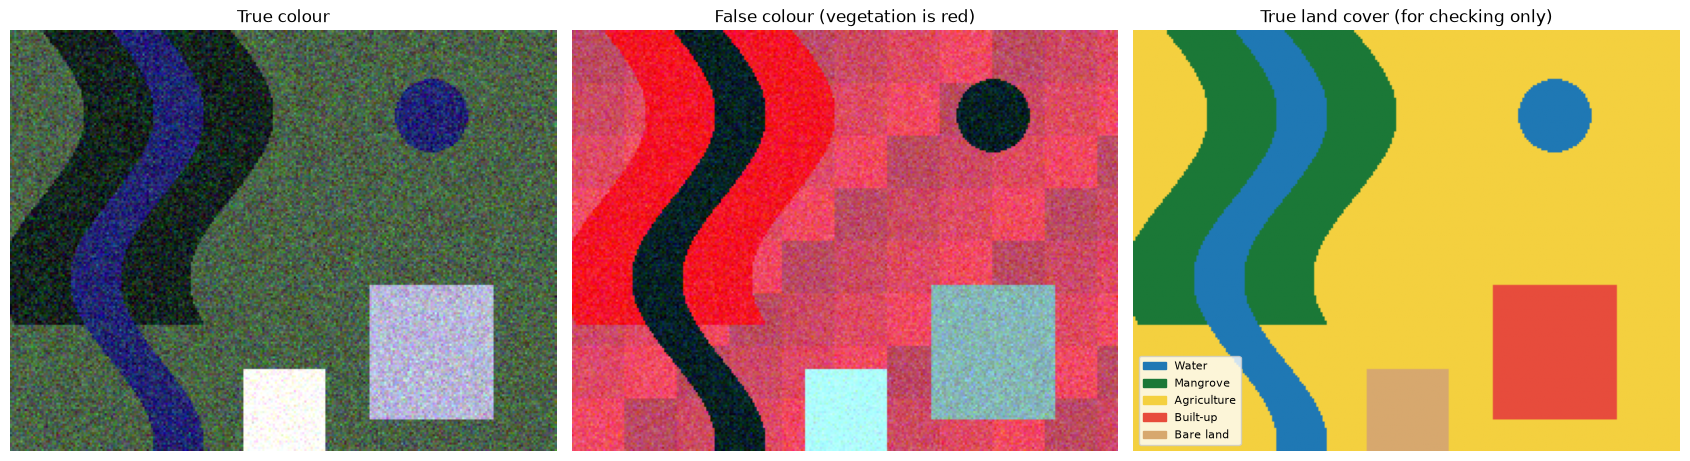

In [3]:
def stretch(band):
    lo, hi = np.percentile(band, [2, 98])
    return np.clip((band - lo) / (hi - lo), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(np.dstack([stretch(red), stretch(green), stretch(blue)]))
axes[0].set_title("True colour")
axes[1].imshow(np.dstack([stretch(nir), stretch(red), stretch(green)]))
axes[1].set_title("False colour (vegetation is red)")
axes[2].imshow(truth, cmap=cmap, vmin=1, vmax=5)
axes[2].set_title("True land cover (for checking only)")
axes[2].legend(handles=[Patch(color=c, label=n) for c, n in zip(COLOURS, CLASSES.values())], fontsize=8, loc="lower left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Step 2: Calculate Spectral Indices**

In [4]:
ndvi = (nir - red) / (nir + red)
ndwi = (green - nir) / (green + nir)
ndbi = (swir - nir) / (swir + nir)

table = pd.DataFrame({name: [idx[truth == k].mean() for k in CLASSES] for name, idx in
                      [("NDVI", ndvi), ("NDWI", ndwi), ("NDBI", ndbi)]}, index=CLASSES.values()).round(2)
table

,NDVI,NDWI,NDBI
Water,-0.35,0.52,-0.28
Mangrove,0.85,-0.72,-0.44
Agriculture,0.64,-0.56,-0.23
Built-up,0.14,-0.21,0.15
Bare land,0.11,-0.21,0.12


This table helps us choose thresholds:
- **Water** is the only class with **positive NDWI**.
- **Built-up** and **bare land** have **positive NDBI**. Bare land has higher NDBI and red reflectance.
- **Mangrove** has the **highest NDVI**.

## **Step 3: Rule-Based Classification**

In [5]:
rule_map = np.select(
    [ndwi > 0,                         # Water
     (ndbi > 0) & (red > 0.18),        # Bare land (bright and dry)
     ndbi > 0,                         # Built-up
     ndvi > 0.74],                     # Mangrove (very high NDVI)
    [1, 5, 4, 2],
    default=3)                         # Everything else: agriculture

## **Step 4: K-Means Unsupervised Classification**
**K-Means** groups pixels into **K groups (clusters)** so that pixels in the same group have similar values. It does not know the class names: it only finds groups.

How it works (in simple steps):
1. Pick K random pixels as the starting **centres**.
2. Give every pixel to its **nearest** centre.
3. Move each centre to the **average** of its pixels.
4. Repeat steps 2 and 3 until the centres stop moving.

We write it with NumPy. (The **scikit-learn** library has a ready-made `KMeans`, but writing it once shows how simple the idea is.)

In [6]:
def kmeans(data, k, iterations=30, seed=0):
    """data: (n_pixels, n_features). Returns labels (0..k-1) and centres."""
    r = np.random.default_rng(seed)
    centres = data[r.choice(len(data), k, replace=False)]
    for _ in range(iterations):
        distances = ((data[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        labels = distances.argmin(axis=1)
        new_centres = np.array([data[labels == j].mean(axis=0) if (labels == j).any() else centres[j] for j in range(k)])
        if np.allclose(new_centres, centres):
            break
        centres = new_centres
    return labels, centres

features = np.stack([b.ravel() for b in image] + [ndvi.ravel(), ndwi.ravel(), ndbi.ravel()], axis=1)
features = (features - features.mean(axis=0)) / features.std(axis=0)       # Put all features on the same scale

labels, centres = kmeans(features, k=5, seed=3)
cluster_map = labels.reshape(rows, cols)
print("Pixels in each cluster:", np.bincount(labels))

Pixels in each cluster: [ 5297  3357 31747  9208  2391]


- `features` has one row per pixel and one column per band or index.
- We **standardise** the features (subtract the mean and divide by the standard deviation), so that no single band dominates just because its numbers are bigger.

## **Step 5: Naming the Clusters**
K-Means only gives cluster numbers (0 to 4). We look at the average index values of each cluster and **decide** which class it is. This is exactly what an analyst does in real unsupervised classification.

In [7]:
cluster_info = pd.DataFrame({
    "pixels": np.bincount(labels),
    "NDVI": [ndvi.ravel()[labels == j].mean() for j in range(5)],
    "NDWI": [ndwi.ravel()[labels == j].mean() for j in range(5)],
    "NDBI": [ndbi.ravel()[labels == j].mean() for j in range(5)],
    "red": [red.ravel()[labels == j].mean() for j in range(5)],
}).round(3)

def name_cluster(row):
    if row["NDWI"] > 0: return 1                      # Water
    if row["NDBI"] > 0: return 5 if row["red"] > 0.18 else 4
    return 2 if row["NDVI"] > 0.74 else 3

cluster_info["class"] = cluster_info.apply(name_cluster, axis=1)
cluster_info["class_name"] = cluster_info["class"].map(CLASSES)
cluster_info

,pixels,NDVI,NDWI,NDBI,red,class,class_name
0,5297,0.132,-0.210,0.141,0.167,4,Built-up
1,3357,-0.235,0.421,-0.634,0.040,1,Water
2,31747,0.640,-0.559,-0.227,0.070,3,Agriculture
3,9208,0.847,-0.715,-0.439,0.030,2,Mangrove
4,2391,-0.516,0.655,0.213,0.040,1,Water


In [8]:
kmeans_map = cluster_info["class"].to_numpy()[cluster_map]

## **Step 6: Accuracy Assessment with Random Points**
In real projects, we visit **random sample points** in the field (or look at high-resolution images) to find the true class. Then we compare it with the map. Here, we take 300 random points and read the true class from our `truth` array.

In [9]:
n_points = 300
sample_r = rng.integers(0, rows, n_points)
sample_c = rng.integers(0, cols, n_points)
reference = truth[sample_r, sample_c]

def confusion_matrix(ref, pred, classes):
    m = pd.DataFrame(0, index=[CLASSES[c] for c in classes], columns=[CLASSES[c] for c in classes])
    for a, b in zip(ref, pred):
        m.loc[CLASSES[b], CLASSES[a]] += 1      # Rows: map class, Columns: reference (true) class
    return m

def accuracy_report(name, class_map):
    predicted = class_map[sample_r, sample_c]
    cm = confusion_matrix(reference, predicted, CLASSES)
    overall = np.trace(cm.values) / cm.values.sum()
    # Kappa: agreement beyond what random chance would give
    expected = (cm.sum(axis=0).values * cm.sum(axis=1).values).sum() / cm.values.sum() ** 2
    kappa = (overall - expected) / (1 - expected)
    print(f"{name}: overall accuracy {overall:.1%}, kappa {kappa:.2f}")
    return cm

cm_rule = accuracy_report("Rule-based", rule_map)
cm_kmeans = accuracy_report("K-Means   ", kmeans_map)
print("\nConfusion matrix for the rule-based map (rows = map, columns = reference):")
cm_rule

Rule-based: overall accuracy 97.3%, kappa 0.96
K-Means   : overall accuracy 95.7%, kappa 0.93

Confusion matrix for the rule-based map (rows = map, columns = reference):


,Water,Mangrove,Agriculture,Built-up,Bare land
Water,36,0,0,0,0
Mangrove,0,44,7,0,0
Agriculture,0,0,171,0,0
Built-up,0,0,0,29,0
Bare land,0,0,0,1,12


**How to read the confusion matrix:**
- The **diagonal** numbers are correct points.
- Numbers **off the diagonal** are mistakes. For example, a number in row "Mangrove" and column "Agriculture" means some agriculture points were wrongly mapped as mangrove.
- **Overall accuracy** = correct points / all points.
- **Kappa** tells how much better the map is than a random guess. Above 0.8 is usually considered very good.

## **Step 7: Final Maps and Area Statistics**

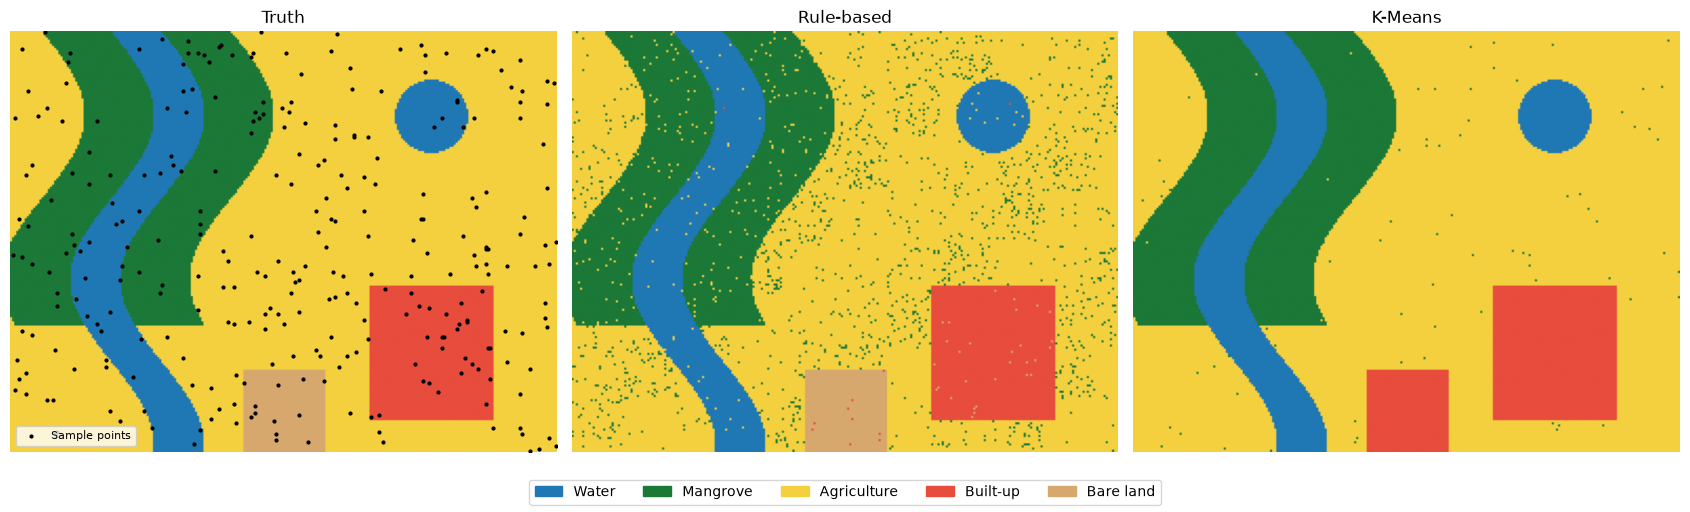

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, m, title in zip(axes, [truth, rule_map, kmeans_map], ["Truth", "Rule-based", "K-Means"]):
    ax.imshow(m, cmap=cmap, vmin=1, vmax=5)
    ax.set_title(title)
    ax.axis("off")
axes[0].scatter(sample_c, sample_r, s=4, color="black", label="Sample points")
axes[0].legend(loc="lower left", fontsize=8)
fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLOURS, CLASSES.values())], loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

In [11]:
pixel_ha = 10 * 10 / 10_000        # One Sentinel-2 pixel = 0.01 hectare
areas = pd.DataFrame({
    "True (ha)": [(truth == k).sum() * pixel_ha for k in CLASSES],
    "Rule-based (ha)": [(rule_map == k).sum() * pixel_ha for k in CLASSES],
    "K-Means (ha)": [(kmeans_map == k).sum() * pixel_ha for k in CLASSES],
}, index=CLASSES.values()).round(1)
areas.loc["Total"] = areas.sum()
areas

,True (ha),Rule-based (ha),K-Means (ha)
Water,57.5,57.0,57.5
Mangrove,91.4,102.4,92.1
Agriculture,318.1,307.7,317.5
Built-up,37.8,37.6,53.0
Bare land,15.2,15.4,0.0
Total,520.0,520.1,520.1


## **What We Learned**
- Spectral indices make classification much easier.
- Rule-based classification needs our knowledge to set thresholds. K-Means finds groups by itself, but we must name them.
- Accuracy must always be checked with **independent reference points**. A map without an accuracy report is not trustworthy.
- In real projects, we would also use **supervised** methods like **Random Forest** (with training samples), and tools like **Google Earth Engine** or **QGIS** plugins.